# Разведочный анализ данных

Данные подготовлены командой `python -m src.data.prepare`.

In [1]:
import json, os, re, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2
from src.config import FIGURES, LABELS, LABEL_NAMES_RU, PROCESSED, REPORTS
from src.data.profanity import mask
from src.error_analysis import MAT, POLITICS

sns.set_theme(style='whitegrid')
FIGURES.mkdir(parents=True, exist_ok=True)
splits = {s: pd.read_parquet(PROCESSED / f'{s}.parquet') for s in ('train', 'val', 'test')}
df = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)
df['label_ru'] = df['label'].map(LABEL_NAMES_RU)
order_ru = [LABEL_NAMES_RU[l] for l in LABELS]
df[['text', 'text_raw', 'label', 'source', 'split']].head().assign(text=lambda d: d['text'].map(mask), text_raw=lambda d: d['text_raw'].map(mask))

,text,text_raw,label,source,split
0,а той самой венесуэле он зачем лишний кишкоблу...,а той самой венесуэле он зачем??? лишний кишко...,neutral,okru,train
1,ну ну не смешите меня,ну ну не смешите меня,neutral,okru,train
2,обоих на кол,обоих на кол!,toxic,okru,train
3,всем привет сомотрела новости и сказали по 10 ...,всем привет сомотрела новости и сказали по 10 ...,neutral,okru,train
4,эвген а отсосать,"эвген , а отсосать....",toxic,okru,train


## 1. Очистка данных

In [2]:
summary = json.loads((REPORTS / 'data_summary.json').read_text(encoding='utf-8'))
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)}, name='значение').to_frame()

,значение
okru_raw,248290
okru_after_empty,248288
okru_after_no_cyrillic,248287
okru_contacts_removed,3842
okru_conflicting_texts,17
okru_exact_duplicates_removed,5475
okru_conflicting_near_groups,3
okru_near_duplicates_removed,379
okru_clean,238591
paradetox_pairs,12204


## 2. Распределение классов

label_ru,нейтральное,оскорбительное,токсичное,всего
split,,,,
train,164762,22530,12539,199831
val,20614,2816,1567,24997
test,20614,2816,1568,24998


label_ru,нейтральное,оскорбительное,токсичное
split,,,
train,82.5%,11.3%,6.3%
val,82.5%,11.3%,6.3%
test,82.5%,11.3%,6.3%


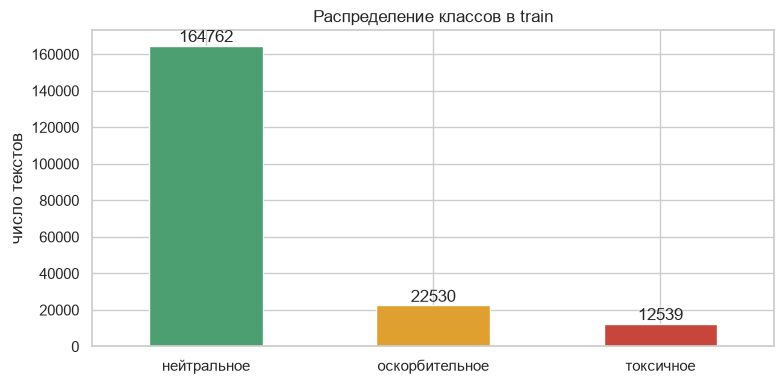

In [3]:
table = pd.crosstab(df['split'], df['label_ru']).reindex(index=['train', 'val', 'test'], columns=order_ru)
share = (table.div(table.sum(axis=1), axis=0) * 100).round(1)
display(table.assign(всего=table.sum(axis=1)))
display(share.astype(str) + '%')

fig, ax = plt.subplots(figsize=(8, 4))
table.loc['train'].plot.bar(ax=ax, color=['#4C9F70', '#E0A030', '#C8453B'])
ax.set_ylabel('число текстов'); ax.set_xlabel('')
ax.set_title('Распределение классов в train')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIGURES / 'class_balance.png', dpi=120); plt.show()

Нейтральных текстов примерно в 13 раз больше, чем токсичных. Поэтому при обучении используются веса классов, а основная метрика macro-F1.

## 3. Источники

In [4]:
pd.crosstab([df['split'], df['source']], df['label_ru']).reindex(columns=order_ru).fillna(0).astype(int)

label_ru         нейтральное  оскорбительное  токсичное
split source                                           
test  okru             19476            2816       1568
      paradetox         1138               0          0
train okru            155803           22530      12539
      paradetox         8959               0          0
val   okru             19476            2816       1567
      paradetox         1138               0          0

## 4. Длина текстов

Длина в секундах оценена по темпу речи около 2,5 слова в секунду.

,count,mean,std,min,50%,90%,95%,max
label_ru,,,,,,,,
нейтральное,205990.0,12.4,15.3,1.0,8.0,26.0,40.0,267.0
оскорбительное,28162.0,14.6,16.7,1.0,9.0,31.0,45.0,176.0
токсичное,15674.0,11.6,12.1,1.0,8.0,23.0,34.0,159.0


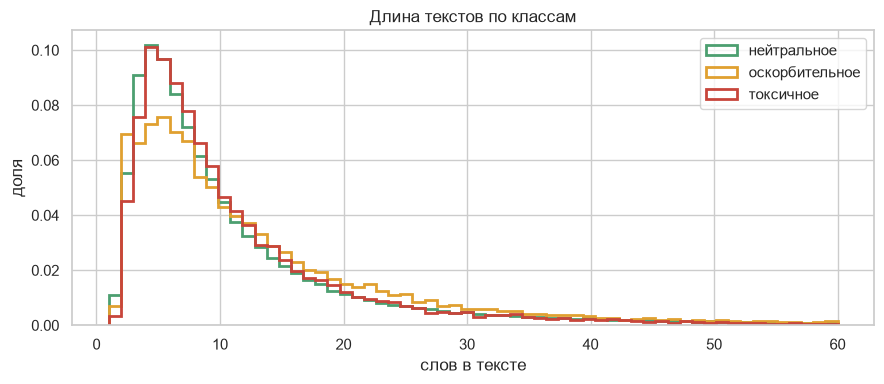

Доля текстов длиннее 60 секунд речи: 0.05 %


In [5]:
df['words'] = df['text'].str.split().str.len()
df['seconds'] = df['words'] / 2.5
display(df.groupby('label_ru')['words'].describe(percentiles=[.5, .9, .95]).reindex(order_ru).round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for label, color in zip(order_ru, ['#4C9F70', '#E0A030', '#C8453B']):
    sub = df[(df['label_ru'] == label) & (df['words'] <= 60)]['words']
    ax.hist(sub, bins=60, density=True, histtype='step', linewidth=2, label=label, color=color)
ax.set_xlabel('слов в тексте'); ax.set_ylabel('доля'); ax.legend(); ax.set_title('Длина текстов по классам')
plt.tight_layout(); plt.savefig(FIGURES / 'length_by_class.png', dpi=120); plt.show()
print('Доля текстов длиннее 60 секунд речи:', round((df['seconds'] > 60).mean() * 100, 2), '%')

Медиана 8 слов, это около 3 секунд речи. Длина у всех классов примерно одинаковая.

## 5. Характерные слова классов

Слова, которые сильнее всего связаны с классом по критерию хи-квадрат.

In [6]:
train = splits['train']
vec = CountVectorizer(min_df=20, max_features=30000, binary=True)
X = vec.fit_transform(train['text'])
vocab = np.array(vec.get_feature_names_out())
top = {}
for label in LABELS:
    y = (train['label'] == label).values
    scores, _ = chi2(X, y)
    pos_rate = np.asarray(X[y].mean(axis=0)).ravel()
    neg_rate = np.asarray(X[~y].mean(axis=0)).ravel()
    scores[pos_rate <= neg_rate] = 0
    top[LABEL_NAMES_RU[label]] = [mask(w) for w in vocab[np.argsort(-scores)[:20]]]
pd.DataFrame(top)

,нейтральное,оскорбительное,токсичное
0,очень,ты,расстрелять
1,спасибо,су*а,кол
2,здоровья,пи**р,надо
3,здравствуйте,бл**ь,стрелять
4,можно,пи***ы,повесить
5,счастья,х**,убить
6,пожалуйста,бл**ь,растрелять
7,есть,твари,сосать
8,днем,тварь,расстреливать
9,добрый,до****б,убивать


У токсичных это слова про насилие, у оскорбительных мат и обидные слова. У нейтральных много поздравлений: спасибо, здоровья, с днем рождения.

## 6. Пересказы из RuParaDetox

In [7]:
para = df[df['source'] == 'paradetox']
print('Нейтральных пересказов:', len(para), '| исходных текстов:', para['group'].nunique())
print('Пересказы одного текста в одной выборке:', bool((para.groupby('group')['split'].nunique() == 1).all()))

Нейтральных пересказов: 11235 | исходных текстов: 7708
Пересказы одного текста в одной выборке: True


## 7. Внешний тест

In [8]:
print('TextDetox: совпадает с основными данными', summary['textdetox_overlap_with_main'], 'из', summary['textdetox_clean'])
ext = pd.read_parquet(PROCESSED / 'external_2ch.parquet')
w = ext['text'].str.split().str.len()
print(f"2ch: {len(ext)} текстов, токсичных {ext['toxic'].mean():.1%}, медиана {w.median():.0f} слов")

TextDetox: совпадает с основными данными 4906 из 4978
2ch: 14037 текстов, токсичных 33.0%, медиана 17 слов


TextDetox не используется, так как почти все его тексты взяты из OK.ru. Для внешней проверки остается 2ch.

## 8. Шум в текстах

In [9]:
from src.data.sources import load_okru
from src.data.text import normalize, has_contacts
raw = load_okru()['text']
checks = {
    'латиница внутри русских слов': r'\b(?=\w*[а-яё])(?=\w*[a-z])\w+\b',
    'растянутые буквы': r'([а-яё])\1{3,}',
    'звездочки внутри слова': r'[а-яё]\*+[а-яё]',
    'маскировка точками': r'\b(?:х|п|б|е|еб|пид|бл)\.{2,}',
}
low = raw.str.lower().astype(object)
rows = {name: low.map(lambda t, rx=re.compile(p): bool(rx.search(t))).mean() for name, p in checks.items()}
rows['телефоны и ссылки'] = raw.astype(object).map(has_contacts).mean()
pd.Series(rows, name='доля в OK.ru').mul(100).round(2).astype(str).add('%').to_frame()

,доля в OK.ru
латиница внутри русских слов,1.39%
растянутые буквы,0.46%
звездочки внутри слова,0.04%
маскировка точками,0.19%
телефоны и ссылки,1.55%


In [10]:
examples = ['ты сегодня кpасавица', 'kрасавицы', 'это у*бище должно', 'прееееееелесть)))',
            'ужасссс', 'ссср', 'дебилом и подоxнешь', '[id274726265|Александр], Вы...', 'ok.ru/profile/1/album/2 красиво']
pd.DataFrame({'исходный': [mask(t) for t in examples], 'после нормализации': [mask(normalize(t)) for t in examples]})

,исходный,после нормализации
0,ты сегодня кpасавица,ты сегодня красавица
1,kрасавицы,красавицы
2,это у*бище должно,это убище должно
3,прееееееелесть))),прелесть
4,ужасссс,ужас
5,ссср,ссср
6,дебилом и подоxнешь,дебилом и подохнешь
7,"[id274726265|Александр], Вы...",александр вы
8,ok.ru/profile/1/album/2 красиво,красиво


Что исправляется:

- латинские буквы внутри русских слов заменяются на русские;
- растянутые буквы сжимаются, СССР и ООО при этом не меняются;
- звездочки внутри слова удаляются;
- объявления с телефонами и ссылками удаляются;
- почти одинаковые тексты (совпадают первые 8 слов) удаляются.

Маскировку точками исправить нельзя, поэтому она остается.

## 9. Мат и политика по классам

,"мат, %","политика, %"
label_ru,,
нейтральное,0.09,3.27
оскорбительное,33.76,11.56
токсичное,20.18,6.21


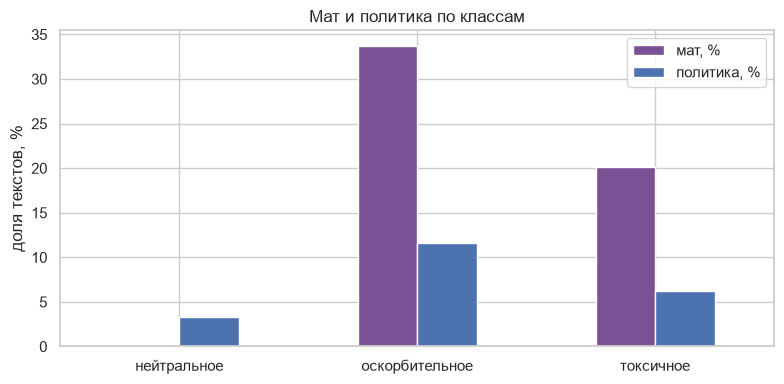

In [11]:
def share(pattern):
    rx = re.compile(pattern)
    return df['text'].astype(object).map(lambda t: bool(rx.search(t))).groupby(df['label_ru']).mean().reindex(order_ru) * 100

bias = pd.DataFrame({'мат, %': share(MAT), 'политика, %': share(POLITICS)}).round(2)
display(bias)
ax = bias.plot.bar(figsize=(8, 4), color=['#7A5195', '#4C72B0'], rot=0)
ax.set_ylabel('доля текстов, %'); ax.set_xlabel(''); ax.set_title('Мат и политика по классам')
plt.tight_layout(); plt.savefig(FIGURES / 'bias_by_class.png', dpi=120); plt.show()

Мат почти не встречается в нейтральных текстах, а в оскорбительных он есть примерно в каждом третьем. Из-за этого модель может считать любой мат оскорблением.

Политические слова в оскорбительных текстах встречаются в 3,4 раза чаще, чем в нейтральных.

## Выводы

- после очистки: train 199831, val 24997, test 24998;
- классы сильно несбалансированы, нейтральных около 82%;
- тексты короткие, как голосовые сообщения;
- классы хорошо различаются по словам;
- нейтральный класс почти без мата, это может мешать модели;
- для внешней проверки используется 2ch, TextDetox исключен.